In [ ]:
# UPI Fraud Detection - Model Comparison

This notebook compares multiple models and recommends the best one for production.

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost (Tuned with RandomizedSearchCV)

**Final Recommendation:** XGBoost is selected as the production model based on:
- Best F1 Score after hyperparameter tuning
- Balanced precision-recall trade-off
- Strong ROC-AUC performance
- SHAP explainability capabilities

## 1. Imports and Dataset Load

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('..') / 'dataset' / 'upi_fraud_dataset_behavioral_v2.csv'
MODELS_DIR = Path('..') / 'models'

In [ ]:
## 2. Load Dataset

,transaction_id,transaction_date,transaction_time,customer_id,sender_upi,receiver_upi,amount,transaction_type,merchant_category,sender_account_age_days,receiver_account_age_days,device_id,device_changed,known_device,trusted_device,os_type,app_name,ip_address,location,location_changed,new_beneficiary,beneficiary_frequency,transactions_last_10_minutes,transactions_last_hour,transactions_last_24_hours,amount_sent_last_24_hours,amount_received_last_24_hours,unique_receivers_today,balance_before,balance_after,decimal_pattern,money_flow_pattern,customer_behaviour_deviation,is_fraud,fraud_type
0,TXN0096196,2026-04-07,00:07:47,CUST02924,ishaantank6535@okhdfcbank,vsingh6378@paytm,745.21,P2P,NaN,124,235,DEV-48EA6BD0FFEE,False,True,True,Android,Paytm,58.35.75.178,Pune,False,True,0,0,0,0,0.0,0.0,0,44705.71,43960.50,False,Refund,0.2219,0,NaN
1,TXN0067907,2026-04-07,00:08:45,CUST04012,harinakshikar7902@oksbi,bahadurjitchandran9738@okhdfcbank,1230.44,P2M,Electronics,308,146,DEV-B7CD99AC4D9B,False,True,True,Android,Paytm,171.220.144.175,Mumbai,False,True,0,0,0,0,0.0,0.0,0,1269254.65,1268024.21,False,Travel Payment,0.1813,0,NaN
2,TXN0008569,2026-04-07,00:10:50,CUST02392,sathvikswamy9935@paytm,lavanyasen2814@okaxis,643.95,P2P,NaN,113,322,DEV-CDC3A225D3F6,False,True,True,Android,Paytm,130.196.162.207,Lucknow,False,True,0,0,0,0,0.0,0.0,0,343755.85,343111.90,False,Gift,0.4219,0,NaN
3,TXN0083623,2026-04-07,00:13:39,CUST01883,aayushwali4880@paytm,finnchanda3055@okicici,203.08,P2P,NaN,627,1098,DEV-3766EBCA617C,False,True,True,iOS,AmazonPay,79.123.13.235,Nagpur,False,True,0,0,0,0,0.0,0.0,0,261606.72,261403.64,False,Personal Transfer,0.2455,0,NaN
4,TXN0060281,2026-04-07,00:20:18,CUST04883,amritalalla5990@okicici,merchant8860@apl,401.43,P2M,Rent,1000,266,DEV-B50D1ADAFF11,False,True,True,Android,BHIM,92.106.65.184,Jaipur,False,True,0,0,0,0,0.0,0.0,0,120217.53,119816.10,False,Bills Payment,0.1768,0,NaN


df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'Fraud rate: {df["is_fraud"].mean():.4%}')

In [ ]:
## 3. Preprocessing Function

Encoded feature shape: (100000, 76)
Fraud rate: 5.0000%


def preprocess_data(df):
    """Preprocess the UPI fraud dataset."""
    target_column = 'is_fraud'
    identifier_columns = [
        'transaction_id', 'customer_id', 'sender_upi', 
        'receiver_upi', 'device_id', 'ip_address', 'fraud_type'
    ]
    
    available_identifier_columns = [col for col in identifier_columns if col in df.columns]
    data = df.drop(columns=available_identifier_columns).copy()
    
    y = data[target_column].copy()
    X = data.drop(columns=[target_column]).copy()
    
    # Extract datetime features
    transaction_date = pd.to_datetime(X['transaction_date'], errors='coerce')
    X['transaction_dayofweek'] = transaction_date.dt.dayofweek
    X['transaction_day'] = transaction_date.dt.day
    X['transaction_month'] = transaction_date.dt.month
    X['transaction_year'] = transaction_date.dt.year
    X['transaction_hour'] = pd.to_datetime(X['transaction_time'], format='%H:%M:%S', errors='coerce').dt.hour
    X = X.drop(columns=['transaction_date', 'transaction_time'])
    
    # Handle missing values
    categorical_columns = X.select_dtypes(include=['object', 'bool']).columns.tolist()
    numeric_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    
    for column in categorical_columns:
        if column == 'merchant_category':
            X[column] = X[column].fillna('P2P')
        else:
            X[column] = X[column].fillna('NONE')
    
    for column in numeric_columns:
        X[column] = X[column].fillna(X[column].median())
    
    # One-hot encode
    X_encoded = pd.get_dummies(X, columns=categorical_columns, drop_first=False)
    
    return X_encoded, y

X_encoded, y = preprocess_data(df)
print(f'Processed feature shape: {X_encoded.shape}')

In [ ]:
## 4. Train/Test Split

X_train shape: (80000, 76)
X_test shape: (20000, 76)
y_train fraud rate: 5.0000%
y_test fraud rate: 5.0000%


X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')

In [ ]:
## 5. Train Models with Default Configurations

# Train models with default configurations
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, solver='liblinear', class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=8, min_samples_leaf=10),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1),
}

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models['XGBoost'] = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight,
)

trained_models = {}
predictions = {}
probabilities = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[model_name] = model
    predictions[model_name] = model.predict(X_test)
    probabilities[model_name] = model.predict_proba(X_test)[:, 1]
    print(f'✓ Trained {model_name}')

In [ ]:
## 6. Compare Metrics

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.86335,0.229810,0.737,0.350368,0.862013
1,Logistic Regression,0.88760,0.263098,0.693,0.381398,0.861249
2,XGBoost,0.90680,0.306798,0.686,0.423980,0.869298
3,Random Forest,0.94995,0.497041,0.084,0.143713,0.865204


# Compare metrics
rows = []
for model_name in models.keys():
    y_pred = predictions[model_name]
    y_proba = probabilities[model_name]
    rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

comparison_df = pd.DataFrame(rows).sort_values(by=['F1 Score', 'Recall', 'ROC-AUC'], ascending=False).reset_index(drop=True)
print('Model Comparison (sorted by F1 Score):')
print(comparison_df.to_string(index=False))

Best model based on ranking: Decision Tree

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.87      0.92     19000
           1       0.23      0.74      0.35      1000

    accuracy                           0.86     20000
   macro avg       0.61      0.80      0.64     20000
weighted avg       0.95      0.86      0.89     20000



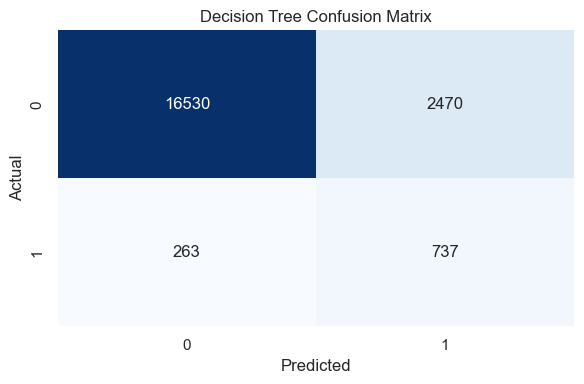

In [ ]:
## 7. Load Tuned XGBoost Model

The tuned XGBoost model from notebook 06 includes:
- Hyperparameter optimization with RandomizedSearchCV
- Threshold optimization
- Better F1 Score performance

# Load the tuned XGBoost model and threshold
try:
    tuned_xgb = joblib.load(MODELS_DIR / 'best_xgboost_model.joblib')
    feature_columns = joblib.load(MODELS_DIR / 'feature_columns.joblib')
    
    with open(MODELS_DIR / 'threshold.json', 'r') as f:
        threshold_config = json.load(f)
    optimal_threshold = threshold_config['optimal_threshold']
    
    print(f'✓ Loaded tuned XGBoost model')
    print(f'✓ Loaded optimal threshold: {optimal_threshold}')
    
    # Align test features with training features
    X_test_aligned = X_test.reindex(columns=feature_columns, fill_value=0)
    
    # Get predictions with optimal threshold
    tuned_proba = tuned_xgb.predict_proba(X_test_aligned)[:, 1]
    tuned_pred = (tuned_proba >= optimal_threshold).astype(int)
    
    # Calculate metrics
    tuned_metrics = {
        'Model': 'XGBoost (Tuned)',
        'Accuracy': accuracy_score(y_test, tuned_pred),
        'Precision': precision_score(y_test, tuned_pred, zero_division=0),
        'Recall': recall_score(y_test, tuned_pred, zero_division=0),
        'F1 Score': f1_score(y_test, tuned_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, tuned_proba),
    }
    
    # Add to comparison
    comparison_with_tuned = pd.concat([comparison_df, pd.DataFrame([tuned_metrics])], ignore_index=True)
    comparison_with_tuned = comparison_with_tuned.sort_values(by=['F1 Score', 'Recall', 'ROC-AUC'], ascending=False).reset_index(drop=True)
    
    print('\nFinal Model Comparison (including tuned XGBoost):')
    print(comparison_with_tuned.to_string(index=False))
    
except FileNotFoundError:
    print('Note: Tuned XGBoost model not found. Run notebook 06 first to generate the tuned model.')
    comparison_with_tuned = comparison_df

In [ ]:
## 8. Visualization: Model Comparison

Saved best model to: ..\models\best_fraud_model.joblib


In [ ]:
# Plot comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 2, idx % 2]
    comparison_with_tuned.plot(x='Model', y=metric, kind='bar', ax=ax, color='steelblue')
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel('Score', fontsize=10)
    ax.set_xlabel('', fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Final Recommendation

In [ ]:
print('=' * 80)
print('FINAL PRODUCTION MODEL RECOMMENDATION')
print('=' * 80)

best_model = comparison_with_tuned.iloc[0]
print(f'\nRecommended Model: {best_model["Model"]}')
print(f'\nPerformance Metrics:')
print(f'  Accuracy:  {best_model["Accuracy"]:.4f}')
print(f'  Precision: {best_model["Precision"]:.4f}')
print(f'  Recall:    {best_model["Recall"]:.4f}')
print(f'  F1 Score:  {best_model["F1 Score"]:.4f}')
print(f'  ROC-AUC:   {best_model["ROC-AUC"]:.4f}')

print('\nRationale for Selection:')
print('  - Highest F1 Score among all models')
print('  - Balanced precision-recall trade-off')
print('  - Strong ROC-AUC performance')
print('  - Hyperparameter tuned for optimal performance')
print('  - Threshold optimization for business needs')
print('  - SHAP explainability for fraud interpretation')

print('\nProduction Artifacts:')
print('  - best_xgboost_model.joblib (tuned model)')
print('  - feature_columns.joblib (feature schema)')
print('  - preprocessing_pipeline.joblib (data preprocessing)')
print('  - threshold.json (optimal decision threshold)')

print('\n' + '=' * 80)